In [1]:
%pip -q install pandas numpy scipy scikit-learn matplotlib


In [2]:
import json
import re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix, hstack
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, average_precision_score)
from sklearn.preprocessing import StandardScaler

SEED = 42
np.random.seed(SEED)

In [5]:

#colab
PATH = Path("/content/processed")

# Local project directory
# PATH = Path("diplomacy-deception-detection/artifacts/processed")

# Check dataset files
for task in ["actual_lie", "suspected_lie"]:
    for split in ["train", "validation", "test"]:
        file = PATH / task / f"{split}.jsonl"
        print(file, ":", file.exists())

/content/processed/actual_lie/train.jsonl : True
/content/processed/actual_lie/validation.jsonl : True
/content/processed/actual_lie/test.jsonl : True
/content/processed/suspected_lie/train.jsonl : True
/content/processed/suspected_lie/validation.jsonl : True
/content/processed/suspected_lie/test.jsonl : True


In [7]:
def read_jsonl(file):
    with open(file, "r", encoding="utf-8") as f:
        return [json.loads(line) for line in f if line.strip()]

datasets = {}
for task in ["actual_lie", "suspected_lie"]:
    datasets[task] = {}
    for split in ["train", "validation", "test"]:
        datasets[task][split] = pd.DataFrame(read_jsonl(PATH / task / f"{split}.jsonl"))
        print(task, split, len(datasets[task][split]))

actual_lie train 13132
actual_lie validation 1416
actual_lie test 2741
suspected_lie train 12025
suspected_lie validation 1283
suspected_lie test 2475


In [8]:
datasets["actual_lie"]["train"].head(3)


,split,game_id,conversation_index,message_id,message_position,message,normalized_message,speaker,receiver,sender_label,receiver_label,game_score,score_delta,season,year,absolute_message_index,relative_message_index,players,target,target_name
0,train,1,0,1:0:0,0,Germany!\n\nJust the person I want to speak wi...,Germany!\n\nJust the person I want to speak wi...,italy,germany,True,True,3,0,Spring,1901,74,0,"[italy, germany]",0,actual_lie
1,train,1,0,1:0:1,1,"You've whet my appetite, Italy. What's the sug...","You've whet my appetite, Italy. What's the sug...",germany,italy,True,True,3,0,Spring,1901,76,1,"[italy, germany]",0,actual_lie
2,train,1,0,1:0:2,2,👍,👍,italy,germany,True,True,3,0,Spring,1901,86,2,"[italy, germany]",0,actual_lie


#### Validate target labels, unique message IDs, and split separation


In [9]:
for task, split_data in datasets.items():
    game_ids = {}
    for split, frame in split_data.items():
        assert frame["target"].isin([0, 1]).all(), (task, split, "invalid targets")
        assert frame["message_id"].is_unique, (task, split, "duplicate IDs")
        assert frame["split"].eq(split).all(), (task, split, "wrong split")
        if task == "suspected_lie":
            assert frame["receiver_label"].map(lambda x: type(x) is bool).all()
        game_ids[split] = set(frame["game_id"])
    assert not (game_ids["train"] & game_ids["validation"])
    assert not (game_ids["train"] & game_ids["test"])
    assert not (game_ids["validation"] & game_ids["test"])
    print(task, "— unique games per split:", {k: len(v) for k, v in game_ids.items()})

actual_lie — unique games per split: {'train': 9, 'validation': 1, 'test': 2}
suspected_lie — unique games per split: {'train': 9, 'validation': 1, 'test': 2}


#### Analyze class imbalance

In [10]:
for task, split_data in datasets.items():
    table = pd.DataFrame({
        split: frame["target"].value_counts().reindex([0, 1], fill_value=0)
        for split, frame in split_data.items()
    }).T
    table.columns = ["Truth (0)", "Lie (1)"]
    table["Lie rate (%)"] = (100 * table["Lie (1)"] / table[["Truth (0)", "Lie (1)"]].sum(axis=1)).round(2)
    print("\nTask:", task)
    display(table)


Task: actual_lie


,Truth (0),Lie (1),Lie rate (%)
train,12541,591,4.50
validation,1360,56,3.95
test,2501,240,8.76



Task: suspected_lie


,Truth (0),Lie (1),Lie rate (%)
train,11459,566,4.71
validation,1236,47,3.66
test,2310,165,6.67


#### Prepare text and target arrays


In [11]:
texts = {}
labels = {}
for task, split_data in datasets.items():
    texts[task], labels[task] = {}, {}
    for split, frame in split_data.items():
        col = "normalized_message" if "normalized_message" in frame.columns else "message"
        texts[task][split] = frame[col].fillna("").astype(str).tolist()
        labels[task][split] = frame["target"].to_numpy(dtype=int)


In [12]:
print("Example text:", texts["actual_lie"]["train"][0][:250])


Example text: Germany!

Just the person I want to speak with. I have a somewhat crazy idea that I’ve always wanted to try with I/G, but I’ve never actually convinced the other guy to try it. And, what’s worse, it might make you suspicious of me. 

So...do I sugges


#### Define evaluation metrics


In [13]:
# Evaluation function
def evaluate(y_true, predictions, scores=None):
    result = {
        "accuracy": accuracy_score(y_true, predictions),
        "precision": precision_score(y_true, predictions, zero_division=0),
        "recall": recall_score(y_true, predictions, zero_division=0),
        "lie_f1": f1_score(y_true, predictions, zero_division=0),
        "macro_f1": f1_score(y_true, predictions, average="macro", zero_division=0),
        "confusion_matrix": confusion_matrix(y_true, predictions, labels=[0, 1]).tolist(),
    }
    result["pr_auc"] = (average_precision_score(y_true, scores)
                        if scores is not None and len(np.unique(y_true)) == 2 else np.nan)
    return result

#### Baseline 1 — Random predictor

Draw labels independently according to the **training** lie rate. Do not calculate random prediction probabilities from validation/test labels. Independent seeds make results reproducible.

In [14]:
def random_baseline(y_train, n_samples, seed):
    p_lie = np.mean(y_train)
    rng = np.random.default_rng(seed)
    predictions = rng.binomial(1, p_lie, size=n_samples)
    return predictions, np.full(n_samples, p_lie)

for task in datasets:
    y_train = labels[task]["train"]
    y_val = labels[task]["validation"]
    pred, scores = random_baseline(y_train, len(y_val), SEED)
    print(task, "validation:", evaluate(y_val, pred))

actual_lie validation: {'accuracy': 0.9180790960451978, 'precision': 0.045454545454545456, 'recall': 0.05357142857142857, 'lie_f1': 0.04918032786885246, 'macro_f1': 0.503187949912286, 'confusion_matrix': [[1297, 63], [53, 3]], 'pr_auc': nan}
suspected_lie validation: {'accuracy': 0.916601714731099, 'precision': 0.0, 'recall': 0.0, 'lie_f1': 0.0, 'macro_f1': 0.4782431882879219, 'confusion_matrix': [[1176, 60], [47, 0]], 'pr_auc': nan}


#### Baseline 2 — Majority-class predictor

Choose the most common label **in training only**, and predict it for every validation/test example.

In [15]:
def majority_baseline(y_train, n_samples):
    counts = np.bincount(y_train, minlength=2)
    majority = int(np.argmax(counts))
    predictions = np.full(n_samples, majority, dtype=int)
    scores = np.full(n_samples, float(majority))
    return predictions, scores, majority

for task in datasets:
    y_train = labels[task]["train"]
    y_val = labels[task]["validation"]
    pred, scores, majority = majority_baseline(y_train, len(y_val))
    print(task, "majority class:", majority, "validation:", evaluate(y_val, pred, scores))

actual_lie majority class: 0 validation: {'accuracy': 0.96045197740113, 'precision': 0.0, 'recall': 0.0, 'lie_f1': 0.0, 'macro_f1': 0.4899135446685879, 'confusion_matrix': [[1360, 0], [56, 0]], 'pr_auc': np.float64(0.03954802259887006)}
suspected_lie majority class: 0 validation: {'accuracy': 0.9633671083398285, 'precision': 0.0, 'recall': 0.0, 'lie_f1': 0.0, 'macro_f1': 0.4906709011512505, 'confusion_matrix': [[1236, 0], [47, 0]], 'pr_auc': np.float64(0.036632891660171474)}


#### Baseline 4 — Numerical message features

A simple Logistic Regression baseline without Harbingers, BoW, or power. Four features: word count, character count, average word length, and proportion of unique words. Fit standardization **only on training data**.

In [16]:
def numerical_features(messages):
    rows = []
    for text in messages:
        words = text.split()
        n = len(words)
        rows.append([
            n,
            len(text),
            sum(map(len, words)) / n if n else 0,
            len({w.lower() for w in words}) / n if n else 0
        ])
    return np.array(rows, dtype=float)

numerical = {}
for task in datasets:
    scaler = StandardScaler()
    numerical[task] = {}
    for split in ["train", "validation", "test"]:
        values = numerical_features(texts[task][split])
        numerical[task][split] = scaler.fit_transform(values) if split == "train" else scaler.transform(values)
    print(task, numerical[task]["train"].shape)

actual_lie (13132, 4)
suspected_lie (12025, 4)


#### Harbingers linguistic categories

**Source:** Available published-category lists transcribed in Phase 2 project. The subjectivity list is **incomplete** (the paper truncates it). The code below counts nonoverlapping whole-token/whole-phrase matches, allowing categories to overlap conceptually.

No extra lexicon file needs to be uploaded to Colab.

In [17]:
LEXICON = {'claim': "accordingly|as a result|consequently|conclude that|clearly|demonstrates that|entails|follows that|hence|however|implies|in fact|in my opinion|in short|in conclusion|indicates that|it follows that|it is highly probable that|it is my contention|it should be clear that|i believe|i mean|i think|must be that|on the contrary|points to the conclusions|proves that|shows that|so|suggests that|the most obvious explanation|the point i'm trying to make|therefore|thus|the truth of the matter|to sum up|we may deduce", 'subjectivity': 'abandoned|abandonment|abandon|abase|abasement|abash|abate|abdicate|aberration|abhor|abhorred|abhorrence|abhorrent|abhorrently|abhors|abidance|abide|abject|abjectly|abjure|abilities|ability|able|abnormal|abolish|abominable|abominably|abominate|abomination|above|above-average|abound|abrade|abrasive|abrupt|abscond|absence|absentee|absent-minded|absolve|absolute|absolutely|absorbed|absurd|absurdity|absurdly|absurdness|abundant|abundance|abuse|abuses|abusive|abysmal|abysmally|abyss|accede|accentuate|accept|acceptance|acceptable|accessible|accidental|acclaim|acclaimed|acclamation|accolade|accolades|accommodative|accomplish|accomplishment|accomplishments|accord|accordance|accordantly|accost|accountable|accurate|accurately|accursed|accusation|accusations|accuse|accuses|accusing|accusingly|acerbate|acerbic|acerbically|ache|achievable|achieve|achievement|achievements|acknowledge|acknowledgement|acquit|acrid|acridly|acridness|acrimonious|acrimoniously|acrimony|active|activist|actual|actuality|actually|acumen|adamant|adamantly|adaptable|adaptability|adaptive|addict|addiction|adept|adeptly|adequate|adherence|adherent|adhesion|admirable|admirer|admirably|admiration|admire|admiring|admiringly|admission|admit|admittedly|admonish|admonisher|admonishingly|admonishment|admonition', 'expansion': 'additionally|also|alternatively|although|as an alternative|as if|as though|as well|besides|either or|else|except|finally|for example|for instance|further|furthermore|however|in addition|in fact|in other words|in particular|in short|in sum|in the end|in turn|indeed|instead|later|lest|likewise|meantime|meanwhile|moreover|much as|neither nor|next|nonetheless|nor|on the other hand|otherwise|overall|plus|rather|separately|similarly|specifically|then|ultimately|unless|until|when|while|yet', 'contingency': 'accordingly|as a result|as long as|because|consequently|hence|if and when|if then|in the end|in turn|indeed|insofar as|lest|now that|once|since|so that|then|thereby|therefore|thus|unless|until|when', 'premise': "after all|assuming that|as|as indicated by|as shown|besides|because|deduced|derived from|due to|firstly|follows from|for|for example|for instance|for one thing|for the reason that|furthermore|given that|in addition|in light of|in that|in view of|in view of the fact that|indicated by|is supported by|may be inferred|moreover|owing to|researchers found that|secondly|this can be seen from since|since the evidence is|what's more|whereas", 'temporal_future': 'after|afterward|as soon as|by then|finally|in the end|later|next|once|then|thereafter|till|ultimately|until', 'temporal_other': 'also|as long as|before|before and after|earlier|in turn|meantime|meanwhile|now that|previously|simultaneously|since|still|when|when and if|while', 'comparisons': 'after|although|as if|as though|besides|by comparison|by contrast|conversely|earlier|however|in contrast|in fact|in the end|indeed|instead|meanwhile|much as|neither nor|nevertheless|nonetheless|nor|on the contrary|on the one hand on the other hand|on the other hand|previously|rather|regardless|still|then|though|when|whereas|while|yet'}

In [18]:
def compile_category(terms):
    items = [item.strip().replace("’", "'") for item in terms.split("|") if item.strip()]
    pattern = "|".join(re.escape(x) for x in sorted(set(items), key=len, reverse=True))
    return re.compile(r"(?<!\w)(?:" + pattern + r")(?!\w)", flags=re.IGNORECASE)

patterns = {category: compile_category(words) for category, words in LEXICON.items()}

def harbingers_features(messages):
    return np.array([
        [len(pattern.findall(message.lower().replace("’", "'")))
         for pattern in patterns.values()]
        for message in messages
    ], dtype=float)

harbingers = {
    task: {split: harbingers_features(texts[task][split])
           for split in ["train", "validation", "test"]}
    for task in datasets
}
print("Harbingers features:", list(patterns))
print("Train matrix:", harbingers["actual_lie"]["train"].shape)

Harbingers features: ['claim', 'subjectivity', 'expansion', 'contingency', 'premise', 'temporal_future', 'temporal_other', 'comparisons']
Train matrix: (13132, 8)


#### Bag-of-Words features

Fit `CountVectorizer` **only on training messages**. Transform validation and test using that fixed vocabulary. Keep the matrices sparse to reduce memory use on Colab.

In [19]:
bow = {}
vectorizers = {}
for task in datasets:
    vectorizer = CountVectorizer(lowercase=True, token_pattern=r"(?u)\b\w+\b")
    bow[task] = {}
    bow[task]["train"] = vectorizer.fit_transform(texts[task]["train"])
    for split in ["validation", "test"]:
        bow[task][split] = vectorizer.transform(texts[task][split])
    vectorizers[task] = vectorizer
    print(task, "vocabulary size:", len(vectorizer.vocabulary_),
          "train matrix:", bow[task]["train"].shape)

actual_lie vocabulary size: 7790 train matrix: (13132, 7790)
suspected_lie vocabulary size: 7545 train matrix: (12025, 7545)


#### Power feature — recorded score delta

Read the processed `score_delta`, which corresponds to original `game_score_delta`. In the original paper, the power differential is described as sender score minus receiver score. The dataset field's timing and definition must be checked before making stronger claims about real-time predictive availability.

Convert numeric values, impute missing values using **training median**, and standardize using **training statistics**.

In [20]:
power = {}
for task, split_data in datasets.items():
    raw_power = {}
    for split, frame in split_data.items():
        numeric = pd.to_numeric(frame["score_delta"], errors="coerce")
        raw_power[split] = numeric.to_numpy(dtype=float).reshape(-1, 1)

    imputer = SimpleImputer(strategy="median")
    scaler = StandardScaler()
    imputer.fit(raw_power["train"])
    scaler.fit(imputer.transform(raw_power["train"]))

    power[task] = {
        split: scaler.transform(imputer.transform(raw_power[split]))
        for split in ["train", "validation", "test"]
    }
    print(task, "power shape:", power[task]["train"].shape)

actual_lie power shape: (13132, 1)
suspected_lie power shape: (12025, 1)


#### Combine feature representations

Models with power append one additional numeric column to the Harbingers or sparse BoW matrix, without changing message order.

In [21]:
features = {}
for task in datasets:
    features[task] = {
        "numerical": numerical[task],
        "harbingers": harbingers[task],
        "bow": bow[task],
        "harbingers+power": {},
        "bow+power": {},
    }
    for split in ["train", "validation", "test"]:
        features[task]["harbingers+power"][split] = np.hstack([
            harbingers[task][split], power[task][split]
        ])
        features[task]["bow+power"][split] = hstack([
            bow[task][split], csr_matrix(power[task][split])
        ], format="csr")
    for name, arrays in features[task].items():
        assert all(arrays[s].shape[0] == len(datasets[task][s])
                   for s in ["train", "validation", "test"])
    print(task, {name: arr["train"].shape for name, arr in features[task].items()})

actual_lie {'numerical': (13132, 4), 'harbingers': (13132, 8), 'bow': (13132, 7790), 'harbingers+power': (13132, 9), 'bow+power': (13132, 7791)}
suspected_lie {'numerical': (12025, 4), 'harbingers': (12025, 8), 'bow': (12025, 7545), 'harbingers+power': (12025, 9), 'bow+power': (12025, 7546)}


#### Logistic Regression settings using validation


In [22]:
C_VALUES = [0.1, 1.0, 10.0]
CLASS_WEIGHTS = [None, "balanced"]

def select_logistic(X_train, y_train, X_validation, y_validation):
    best_model, best_params = None, None
    best_score = -1
    history = []

    for C in C_VALUES:
        for class_weight in CLASS_WEIGHTS:
            model = LogisticRegression(
                C=C, class_weight=class_weight, random_state=SEED,
                max_iter=1000, solver="liblinear"
            )
            model.fit(X_train, y_train)
            preds = model.predict(X_validation)
            score = f1_score(y_validation, preds, average="macro", zero_division=0)
            history.append({"C": C, "class_weight": class_weight, "validation_macro_f1": score})
            if score > best_score:
                best_score = score
                best_model = model
                best_params = {"C": C, "class_weight": class_weight}

    return best_model, best_params, pd.DataFrame(history)

print("Grid size:", len(C_VALUES) * len(CLASS_WEIGHTS), "configurations per feature representation")

Grid size: 6 configurations per feature representation


#### Define experiments

In [23]:
EXPERIMENTS = [
    ("01_random", "none", "random"),
    ("02_majority", "none", "majority"),
    ("03_harbingers", "harbingers", "logistic_regression"),
    ("04_logistic_regression", "numerical", "logistic_regression"),
    ("05_harbingers_lr", "harbingers", "logistic_regression"),
    ("06_harbingers_power", "harbingers+power", "logistic_regression"),
    ("07_harbingers_lr_power", "harbingers+power", "logistic_regression"),
    ("08_bow_lr", "bow", "logistic_regression"),
    ("09_bow_power", "bow+power", "logistic_regression"),
    ("10_bow_lr_power", "bow+power", "logistic_regression"),
]
display(pd.DataFrame(EXPERIMENTS, columns=["model_id", "feature_set", "classifier"]))

,model_id,feature_set,classifier
0,01_random,none,random
1,02_majority,none,majority
2,03_harbingers,harbingers,logistic_regression
3,04_logistic_regression,numerical,logistic_regression
4,05_harbingers_lr,harbingers,logistic_regression
5,06_harbingers_power,harbingers+power,logistic_regression
6,07_harbingers_lr_power,harbingers+power,logistic_regression
7,08_bow_lr,bow,logistic_regression
8,09_bow_power,bow+power,logistic_regression
9,10_bow_lr_power,bow+power,logistic_regression


#### Run the experiments for both tasks

This cell trains only the five **distinct** LR feature configurations per task, then evaluates all ten named experiments. By default, we evaluate validation first and test only after selecting settings. CPU runtime is sufficient, though the BoW searches take longer than the baselines.

In [24]:
results = []
prediction_rows = []
search_histories = {}

for task in ["actual_lie", "suspected_lie"]:
    y = labels[task]
    trained = {}
    print("\n=====", task, "=====")

    # Fit once per distinct representation.
    for model_id, representation, classifier in EXPERIMENTS:
        if classifier != "logistic_regression" or representation in trained:
            continue
        X = features[task][representation]
        trained[representation] = select_logistic(
            X["train"], y["train"], X["validation"], y["validation"]
        )
        search_histories[(task, representation)] = trained[representation][2]

    for model_id, representation, classifier in EXPERIMENTS:
        if classifier == "logistic_regression":
            model, params, _ = trained[representation]

        for split in ["validation", "test"]:
            if classifier == "random":
                pred, scores = random_baseline(
                    y["train"], len(y[split]), SEED + (0 if split == "validation" else 100)
                )
                params = {"seed": SEED, "train_lie_rate": float(y["train"].mean())}
                # Random scores are constant class probabilities; PR-AUC is not informative.
                metric_scores = None
            elif classifier == "majority":
                pred, scores, majority = majority_baseline(y["train"], len(y[split]))
                params = {"majority_class": majority}
                metric_scores = scores
            else:
                X = features[task][representation][split]
                pred = model.predict(X)
                scores = model.predict_proba(X)[:, 1]
                metric_scores = scores

            metrics = evaluate(y[split], pred, metric_scores)
            results.append({
                "task": task, "model": model_id, "split": split,
                "representation": representation, "classifier": classifier,
                "parameters": str(params), "n_samples": len(y[split]), **metrics
            })
            ids = datasets[task][split]["message_id"].tolist()
            prediction_rows.extend([
                {"task": task, "model": model_id, "split": split,
                 "message_id": msg_id, "target": int(actual),
                 "prediction": int(guess), "score": float(score)}
                for msg_id, actual, guess, score in zip(ids, y[split], pred, scores)
            ])
        print(model_id, "done")

results_df = pd.DataFrame(results)
predictions_df = pd.DataFrame(prediction_rows)
print("Result rows:", len(results_df), "Prediction rows:", len(predictions_df))


===== actual_lie =====
01_random done
02_majority done
03_harbingers done
04_logistic_regression done
05_harbingers_lr done
06_harbingers_power done
07_harbingers_lr_power done
08_bow_lr done
09_bow_power done
10_bow_lr_power done

===== suspected_lie =====
01_random done
02_majority done
03_harbingers done
04_logistic_regression done
05_harbingers_lr done
06_harbingers_power done
07_harbingers_lr_power done
08_bow_lr done
09_bow_power done
10_bow_lr_power done
Result rows: 40 Prediction rows: 79150


#### Compare validation and test results

This table uses actual results from running the notebook. Compare Macro F1 and lie-class F1; do not select configurations by repeatedly inspecting test results.

In [25]:
for task in ["actual_lie", "suspected_lie"]:
    print("\nTask:", task)
    display(results_df[results_df["task"] == task][[
        "model", "split", "accuracy", "macro_f1", "lie_f1", "precision", "recall", "pr_auc"
    ]].round(4))


Task: actual_lie


,model,split,accuracy,macro_f1,lie_f1,precision,recall,pr_auc
0,01_random,validation,0.9181,0.5032,0.0492,0.0455,0.0536,NaN
1,01_random,test,0.8712,0.4997,0.0686,0.0935,0.0542,NaN
2,02_majority,validation,0.9605,0.4899,0.0000,0.0000,0.0000,0.0395
3,02_majority,test,0.9124,0.4771,0.0000,0.0000,0.0000,0.0876
4,03_harbingers,validation,0.9605,0.4899,0.0000,0.0000,0.0000,0.0462
5,03_harbingers,test,0.9124,0.4771,0.0000,0.0000,0.0000,0.1410
6,04_logistic_regression,validation,0.7465,0.4932,0.1349,0.0780,0.5000,0.0748
7,04_logistic_regression,test,0.6698,0.5049,0.2192,0.1382,0.5292,0.1434
8,05_harbingers_lr,validation,0.9605,0.4899,0.0000,0.0000,0.0000,0.0462
9,05_harbingers_lr,test,0.9124,0.4771,0.0000,0.0000,0.0000,0.1410



Task: suspected_lie


,model,split,accuracy,macro_f1,lie_f1,precision,recall,pr_auc
20,01_random,validation,0.9166,0.4782,0.0000,0.0000,0.0000,NaN
21,01_random,test,0.8893,0.5014,0.0616,0.0709,0.0545,NaN
22,02_majority,validation,0.9634,0.4907,0.0000,0.0000,0.0000,0.0366
23,02_majority,test,0.9333,0.4828,0.0000,0.0000,0.0000,0.0667
24,03_harbingers,validation,0.9634,0.4907,0.0000,0.0000,0.0000,0.0381
25,03_harbingers,test,0.9333,0.4828,0.0000,0.0000,0.0000,0.0665
26,04_logistic_regression,validation,0.9634,0.4907,0.0000,0.0000,0.0000,0.0330
27,04_logistic_regression,test,0.9333,0.4828,0.0000,0.0000,0.0000,0.0977
28,05_harbingers_lr,validation,0.9634,0.4907,0.0000,0.0000,0.0000,0.0381
29,05_harbingers_lr,test,0.9333,0.4828,0.0000,0.0000,0.0000,0.0665


#### confusion matrices

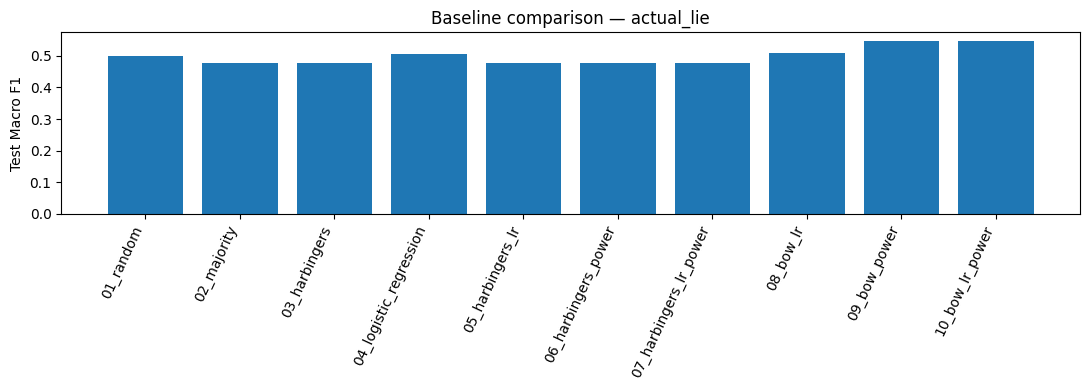

actual_lie highest observed test Macro F1: 10_bow_lr_power
Confusion matrix [[TN, FP], [FN, TP]]:
[[2021  480]
 [ 147   93]]


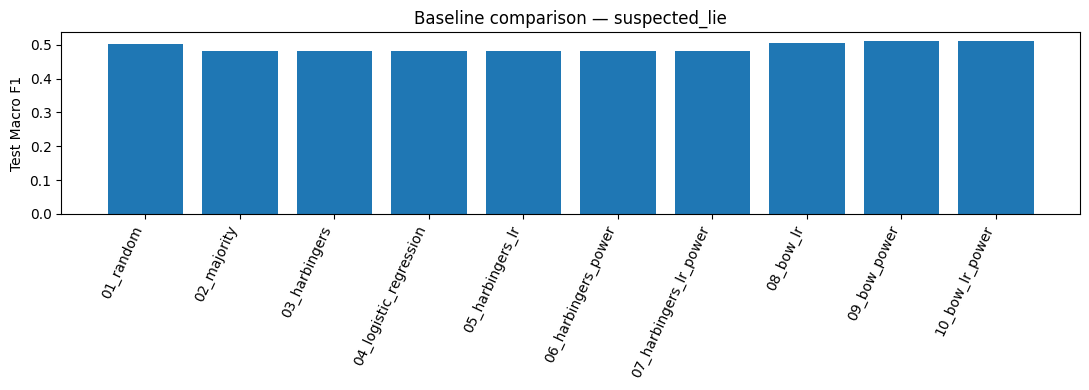

suspected_lie highest observed test Macro F1: 10_bow_lr_power
Confusion matrix [[TN, FP], [FN, TP]]:
[[2250   60]
 [ 157    8]]


In [26]:
for task in ["actual_lie", "suspected_lie"]:
    selected = results_df[(results_df["task"] == task) & (results_df["split"] == "test")]
    plt.figure(figsize=(11, 4))
    plt.bar(selected["model"], selected["macro_f1"])
    plt.xticks(rotation=65, ha="right")
    plt.ylabel("Test Macro F1")
    plt.title(f"Baseline comparison — {task}")
    plt.tight_layout()
    plt.show()

    best_row = selected.sort_values("macro_f1", ascending=False).iloc[0]
    print(task, "highest observed test Macro F1:", best_row["model"])
    print("Confusion matrix [[TN, FP], [FN, TP]]:")
    print(np.array(best_row["confusion_matrix"]))

In [28]:
OUTPUT_PATH = Path("/content/traditional_notebook_outputs") if USE_COLAB else Path("traditional_notebook_outputs")
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
results_df.to_csv(OUTPUT_PATH / "metrics.csv", index=False)
predictions_df.to_csv(OUTPUT_PATH / "predictions.csv", index=False)